In [2]:
import pandas as pd

df = pd.read_csv(r"C:\07th sem\ML\Mini project\AI_Human_Naive_Bayes\dataset\AI_Human.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Shape: (487235, 2)

Columns:
Index(['text', 'generated'], dtype='object')

First 5 rows:


,text,generated
0,Cars. Cars have been around since they became ...,0.0
1,Transportation is a large necessity in most co...,0.0
2,"""America's love affair with it's vehicles seem...",0.0
3,How often do you ride in a car? Do you drive a...,0.0
4,Cars are a wonderful thing. They are perhaps o...,0.0



Data types:
text          object
generated    float64
dtype: object

Missing values:
text         0
generated    0
dtype: int64

Duplicate rows: 0


In [3]:
df = df.dropna()
df = df.drop_duplicates()

print("Shape after cleaning:", df.shape)
print("Missing values:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape after cleaning: (487235, 2)
Missing values:
text         0
generated    0
dtype: int64
Duplicate rows: 0


In [4]:
print(df["generated"].value_counts())
print("\nPercentage distribution:")
print(df["generated"].value_counts(normalize=True) * 100)

generated
0.0    305797
1.0    181438
Name: count, dtype: int64

Percentage distribution:
generated
0.0    62.761706
1.0    37.238294
Name: proportion, dtype: float64


In [5]:
#Check the actual text data
for i in range(3):
    print(f"--- Sample {i+1} ---")
    print("Text:", df["text"].iloc[i])
    print("Label:", df["generated"].iloc[i])
    print()

--- Sample 1 ---
Text: Cars. Cars have been around since they became famous in the 1900s, when Henry Ford created and built the first ModelT. Cars have played a major role in our every day lives since then. But now, people are starting to question if limiting car usage would be a good thing. To me, limiting the use of cars might be a good thing to do.

In like matter of this, article, "In German Suburb, Life Goes On Without Cars," by Elizabeth Rosenthal states, how automobiles are the linchpin of suburbs, where middle class families from either Shanghai or Chicago tend to make their homes. Experts say how this is a huge impediment to current efforts to reduce greenhouse gas emissions from tailpipe. Passenger cars are responsible for 12 percent of greenhouse gas emissions in Europe...and up to 50 percent in some carintensive areas in the United States. Cars are the main reason for the greenhouse gas emissions because of a lot of people driving them around all the time getting where they

In [6]:
#Create a cleaned text column
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df["clean_text"] = df["text"].apply(clean_text)

print(df[["text", "clean_text"]].head(3))

                                                text  \
0  Cars. Cars have been around since they became ...   
1  Transportation is a large necessity in most co...   
2  "America's love affair with it's vehicles seem...   

                                          clean_text  
0  cars cars have been around since they became f...  
1  transportation is a large necessity in most co...  
2  america s love affair with it s vehicles seems...  


In [7]:
#removing the stop words 
import nltk

nltk.download("stopwords")

from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

def remove_stopwords(text):
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

df["clean_text"] = df["clean_text"].apply(remove_stopwords)

print(df["clean_text"].head(3))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\tarun\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


0    cars cars around since became famous henry for...
1    transportation large necessity countries world...
2    america love affair vehicles seems cooling say...
Name: clean_text, dtype: object


In [8]:
#Separate Features and Target
X = df["clean_text"]
y = df["generated"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFirst text:")
print(X.iloc[0])

print("\nFirst label:")
print(y.iloc[0])

X shape: (487235,)
y shape: (487235,)

First text:
cars cars around since became famous henry ford created built first modelt cars played major role every day lives since people starting question limiting car usage would good thing limiting use cars might good thing like matter article german suburb life goes without cars elizabeth rosenthal states automobiles linchpin suburbs middle class families either shanghai chicago tend make homes experts say huge impediment current efforts reduce greenhouse gas emissions tailpipe passenger cars responsible percent greenhouse gas emissions europe percent carintensive areas united states cars main reason greenhouse gas emissions lot people driving around time getting need go article paris bans driving due smog robert duffer says paris days nearrecord pollution enforced partial driving ban clear air global city also says monday motorist evennumbered license plates ordered leave cars home fined euro fine order would applied oddnumbered plates follo

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining label distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting label distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training samples: 389788
Testing samples: 97447

Training label distribution:
generated
0.0    62.761809
1.0    37.238191
Name: proportion, dtype: float64

Testing label distribution:
generated
0.0    62.761296
1.0    37.238704
Name: proportion, dtype: float64


In [10]:
#Create TF-IDF features
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (389788, 6495499)
Testing TF-IDF shape: (97447, 6495499)


In [11]:
print("Training matrix memory:",
      (X_train_tfidf.data.nbytes +
       X_train_tfidf.indices.nbytes +
       X_train_tfidf.indptr.nbytes) / (1024 ** 3),
      "GB")

Training matrix memory: 1.3223303593695164 GB


In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=50000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

print(
    "Training matrix memory:",
    (
        X_train_tfidf.data.nbytes +
        X_train_tfidf.indices.nbytes +
        X_train_tfidf.indptr.nbytes
    ) / (1024 ** 3),
    "GB"
)

Training TF-IDF shape: (389788, 50000)
Testing TF-IDF shape: (97447, 50000)
Training matrix memory: 0.8372955620288849 GB


In [20]:
from sklearn.naive_bayes import ComplementNB

cnb_model = ComplementNB()

cnb_model.fit(X_train_tfidf, y_train)

print("ComplementNB model trained successfully.")

ComplementNB model trained successfully.


In [21]:
y_pred_cnb = cnb_model.predict(X_test_tfidf)

print("Predictions completed.")
print("Number of predictions:", len(y_pred_cnb))
print("First 10 predictions:", y_pred_cnb[:10])

Predictions completed.
Number of predictions: 97447
First 10 predictions: [0. 1. 1. 1. 0. 0. 1. 0. 1. 1.]


In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred_cnb)
precision = precision_score(y_test, y_pred_cnb)
recall = recall_score(y_test, y_pred_cnb)
f1 = f1_score(y_test, y_pred_cnb)

print("ComplementNB Results")
print("--------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)

ComplementNB Results
--------------------
Accuracy : 0.9757714449906103
Precision: 0.9668382089880838
Recall   : 0.9681437389770723
F1-Score : 0.9674905335628228


In [23]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_cnb)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[59954  1205]
 [ 1156 35132]]


In [24]:
from sklearn.metrics import roc_auc_score

y_prob_cnb = cnb_model.predict_proba(X_test_tfidf)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob_cnb)

print("ComplementNB ROC-AUC:", roc_auc)


ComplementNB ROC-AUC: 0.9969607965834162


In [26]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "alpha": [0.1, 0.5, 1.0, 2.0]
}

grid_cnb = GridSearchCV(
    estimator=ComplementNB(),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=1
)

grid_cnb.fit(X_train_tfidf, y_train)

print("Best Alpha:", grid_cnb.best_params_["alpha"])
print("Best Cross-Validation F1:", grid_cnb.best_score_)

Best Alpha: 0.1
Best Cross-Validation F1: 0.9701458679062531


In [27]:
best_cnb = grid_cnb.best_estimator_

y_pred_cnb_optimized = best_cnb.predict(X_test_tfidf)

print("Optimized ComplementNB predictions completed.")

Optimized ComplementNB predictions completed.


In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_opt = accuracy_score(y_test, y_pred_cnb_optimized)
precision_opt = precision_score(y_test, y_pred_cnb_optimized)
recall_opt = recall_score(y_test, y_pred_cnb_optimized)
f1_opt = f1_score(y_test, y_pred_cnb_optimized)

print("Optimized ComplementNB Results")
print("-----------------------------")
print("Accuracy :", accuracy_opt)
print("Precision:", precision_opt)
print("Recall   :", recall_opt)
print("F1-Score :", f1_opt)

Optimized ComplementNB Results
-----------------------------
Accuracy : 0.9774749350929223
Precision: 0.9701574868301294
Recall   : 0.9693287037037037
F1-Score : 0.9697429181887105


In [29]:
from sklearn.metrics import roc_auc_score

y_prob_cnb_optimized = best_cnb.predict_proba(X_test_tfidf)[:, 1]

roc_auc_opt = roc_auc_score(
    y_test,
    y_prob_cnb_optimized
)

print("Optimized ComplementNB ROC-AUC:", roc_auc_opt)

Optimized ComplementNB ROC-AUC: 0.9973831824876166


In [30]:
from sklearn.naive_bayes import MultinomialNB

mnb_model = MultinomialNB()

mnb_model.fit(X_train_tfidf, y_train)

print("MultinomialNB model trained successfully.")

MultinomialNB model trained successfully.


In [31]:
y_pred_mnb = mnb_model.predict(X_test_tfidf)

print("Predictions completed.")
print("Number of predictions:", len(y_pred_mnb))
print("First 10 predictions:", y_pred_mnb[:10])

Predictions completed.
Number of predictions: 97447
First 10 predictions: [0. 1. 1. 1. 0. 0. 1. 0. 1. 1.]


In [32]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_mnb = accuracy_score(y_test, y_pred_mnb)
precision_mnb = precision_score(y_test, y_pred_mnb)
recall_mnb = recall_score(y_test, y_pred_mnb)
f1_mnb = f1_score(y_test, y_pred_mnb)

print("MultinomialNB Results")
print("---------------------")
print("Accuracy :", accuracy_mnb)
print("Precision:", precision_mnb)
print("Recall   :", recall_mnb)
print("F1-Score :", f1_mnb)

MultinomialNB Results
---------------------
Accuracy : 0.9764076882818352
Precision: 0.9754903332307434
Recall   : 0.9607859347442681
F1-Score : 0.9680823001846478


In [33]:
from sklearn.metrics import roc_auc_score

y_prob_mnb = mnb_model.predict_proba(X_test_tfidf)[:, 1]

roc_auc_mnb = roc_auc_score(
    y_test,
    y_prob_mnb
)

print("MultinomialNB ROC-AUC:", roc_auc_mnb)

MultinomialNB ROC-AUC: 0.9969607965834162


In [34]:
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import MultinomialNB

param_grid_mnb = {
    "alpha": [0.1, 0.5, 1.0, 2.0]
}

grid_mnb = GridSearchCV(
    estimator=MultinomialNB(),
    param_grid=param_grid_mnb,
    cv=5,
    scoring="f1",
    n_jobs=1
)

grid_mnb.fit(X_train_tfidf, y_train)

print("Best Alpha:", grid_mnb.best_params_["alpha"])
print("Best Cross-Validation F1:", grid_mnb.best_score_)

Best Alpha: 0.1
Best Cross-Validation F1: 0.9703339415220997


In [35]:
best_mnb = grid_mnb.best_estimator_

y_pred_mnb_optimized = best_mnb.predict(X_test_tfidf)

print("Optimized MultinomialNB predictions completed.")

Optimized MultinomialNB predictions completed.


In [36]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_mnb_opt = accuracy_score(y_test, y_pred_mnb_optimized)
precision_mnb_opt = precision_score(y_test, y_pred_mnb_optimized)
recall_mnb_opt = recall_score(y_test, y_pred_mnb_optimized)
f1_mnb_opt = f1_score(y_test, y_pred_mnb_optimized)

print("Optimized MultinomialNB Results")
print("--------------------------------")
print("Accuracy :", accuracy_mnb_opt)
print("Precision:", precision_mnb_opt)
print("Recall   :", recall_mnb_opt)
print("F1-Score :", f1_mnb_opt)

Optimized MultinomialNB Results
--------------------------------
Accuracy : 0.9779469865670569
Precision: 0.9779364412711746
Recall   : 0.9624944885361552
F1-Score : 0.9701540213602211


In [37]:
from sklearn.metrics import roc_auc_score

y_prob_mnb_optimized = best_mnb.predict_proba(X_test_tfidf)[:, 1]

roc_auc_mnb_opt = roc_auc_score(
    y_test,
    y_prob_mnb_optimized
)

print("Optimized MultinomialNB ROC-AUC:", roc_auc_mnb_opt)

Optimized MultinomialNB ROC-AUC: 0.9973831824876165


In [38]:
from sklearn.metrics import confusion_matrix

cm_cnb_opt = confusion_matrix(
    y_test,
    y_pred_cnb_optimized
)

print("Optimized ComplementNB Confusion Matrix:")
print(cm_cnb_opt)

Optimized ComplementNB Confusion Matrix:
[[60077  1082]
 [ 1113 35175]]


In [39]:
from sklearn.metrics import confusion_matrix

cm_mnb_opt = confusion_matrix(
    y_test,
    y_pred_mnb_optimized
)

print("Optimized MultinomialNB Confusion Matrix:")
print(cm_mnb_opt)

Optimized MultinomialNB Confusion Matrix:
[[60371   788]
 [ 1361 34927]]


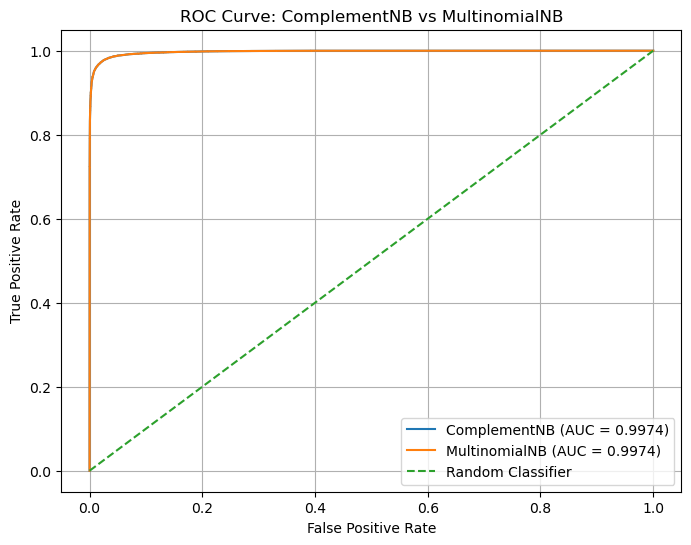

In [40]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr_cnb, tpr_cnb, _ = roc_curve(y_test, y_prob_cnb_optimized)
fpr_mnb, tpr_mnb, _ = roc_curve(y_test, y_prob_mnb_optimized)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_cnb,
    tpr_cnb,
    label=f"ComplementNB (AUC = {roc_auc_opt:.4f})"
)

plt.plot(
    fpr_mnb,
    tpr_mnb,
    label=f"MultinomialNB (AUC = {roc_auc_mnb_opt:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: ComplementNB vs MultinomialNB")
plt.legend()
plt.grid()
plt.show()

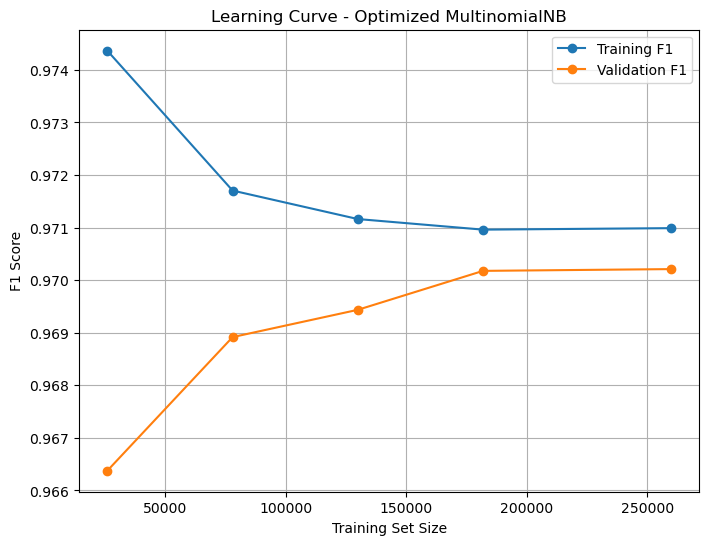

In [42]:
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt

train_sizes, train_scores, validation_scores = learning_curve(
    best_mnb,
    X_train_tfidf,
    y_train,
    train_sizes=[0.1, 0.3, 0.5, 0.7, 1.0],
    cv=3,
    scoring="f1",
    n_jobs=1
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

plt.figure(figsize=(8, 6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training F1"
)

plt.plot(
    train_sizes,
    validation_mean,
    marker="o",
    label="Validation F1"
)

plt.xlabel("Training Set Size")
plt.ylabel("F1 Score")
plt.title("Learning Curve - Optimized MultinomialNB")
plt.legend()
plt.grid()
plt.show()

In [43]:
results = pd.DataFrame({
    "Model": [
        "ComplementNB",
        "MultinomialNB"
    ],
    
    "Best Alpha": [
        grid_cnb.best_params_["alpha"],
        grid_mnb.best_params_["alpha"]
    ],
    
    "CV F1": [
        grid_cnb.best_score_,
        grid_mnb.best_score_
    ],
    
    "Accuracy": [
        accuracy_opt,
        accuracy_mnb_opt
    ],
    
    "Precision": [
        precision_opt,
        precision_mnb_opt
    ],
    
    "Recall": [
        recall_opt,
        recall_mnb_opt
    ],
    
    "F1-Score": [
        f1_opt,
        f1_mnb_opt
    ],
    
    "ROC-AUC": [
        roc_auc_opt,
        roc_auc_mnb_opt
    ]
})

display(results.round(4))

,Model,Best Alpha,CV F1,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,ComplementNB,0.1,0.9701,0.9775,0.9702,0.9693,0.9697,0.9974
1,MultinomialNB,0.1,0.9703,0.9779,0.9779,0.9625,0.9702,0.9974
